/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 197MB/s] 
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:163: FutureWarning: The loss 'log' was deprecated in v1.1 and will be removed in version 1.3. Use `loss='l

Model saved to sgd_classifier_save_model.pkl
Validation Classification Report:
              precision    recall  f1-score   support

         ALM       1.00      1.00      1.00        26
   M in Situ       0.87      0.83      0.85        24
          NM       0.95      1.00      0.97        18
         SSM       0.85      0.85      0.85        20

    accuracy                           0.92        88
   macro avg       0.92      0.92      0.92        88
weighted avg       0.92      0.92      0.92        88

Validation Confusion Matrix:
[[26  0  0  0]
 [ 0 20  1  3]
 [ 0  0 18  0]
 [ 0  3  0 17]]


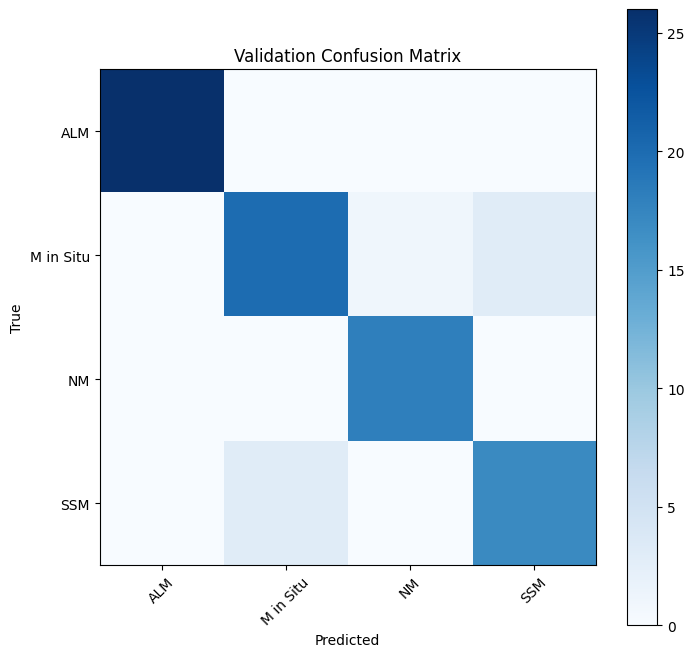

Test Classification Report:
              precision    recall  f1-score   support

         ALM       1.00      1.00      1.00        26
   M in Situ       0.87      0.83      0.85        24
          NM       0.95      1.00      0.97        18
         SSM       0.85      0.85      0.85        20

    accuracy                           0.92        88
   macro avg       0.92      0.92      0.92        88
weighted avg       0.92      0.92      0.92        88

Test Confusion Matrix:
[[26  0  0  0]
 [ 0 20  1  3]
 [ 0  0 18  0]
 [ 0  3  0 17]]


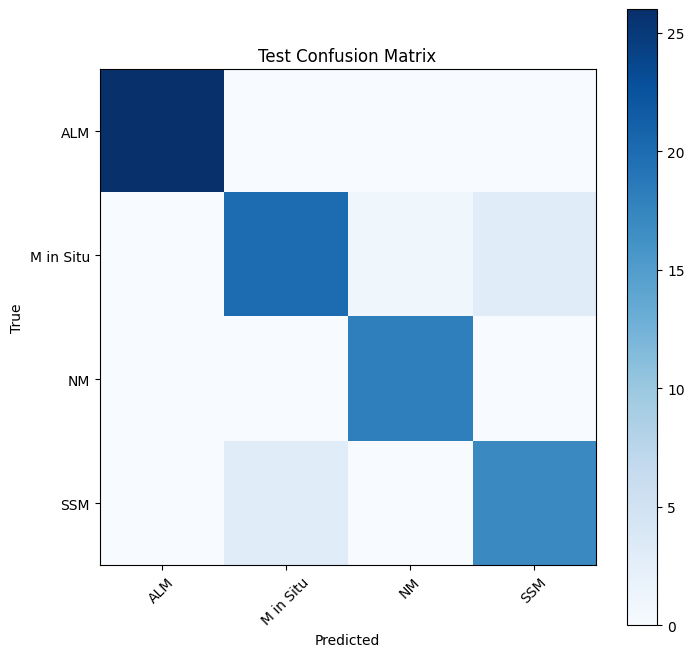

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import joblib  
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


train_dir = '/kaggle/input/save-train'
val_dir = '/kaggle/input/test-save'
test_dir = '/kaggle/input/test-save'


data_transforms = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms)


train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)


resnet34 = models.resnet34(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet34.children())[:-1]).to(device)
feature_extractor.eval() 


def extract_features(data_loader):
    features = []
    labels = []
    
    with torch.no_grad():
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1)  # Flatten the output
            features.append(output.cpu().numpy())
            labels.append(lbls.numpy())
    
    return np.concatenate(features), np.concatenate(labels)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)
test_features, test_labels = extract_features(test_loader)


scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
val_features = scaler.transform(val_features)
test_features = scaler.transform(test_features)


sgd_classifier = SGDClassifier(loss='log', max_iter=15000, tol=1e-3, random_state=42)
sgd_classifier.fit(train_features, train_labels)


model_save_path = 'sgd_classifier_save_model.pkl'
joblib.dump(sgd_classifier, model_save_path)
print(f"Model saved to {model_save_path}")


val_predictions = sgd_classifier.predict(val_features)
test_predictions = sgd_classifier.predict(test_features)


print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions, target_names=val_dataset.classes))

print("Validation Confusion Matrix:")
conf_mat_val = confusion_matrix(val_labels, val_predictions)
print(conf_mat_val)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_val, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(val_dataset.classes)), val_dataset.classes, rotation=45)
plt.yticks(np.arange(len(val_dataset.classes)), val_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.show()


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions, target_names=test_dataset.classes))

print("Test Confusion Matrix:")
conf_mat_test = confusion_matrix(test_labels, test_predictions)
print(conf_mat_test)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_test, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(test_dataset.classes)), test_dataset.classes, rotation=45)
plt.yticks(np.arange(len(test_dataset.classes)), test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Confusion Matrix')
plt.show()


Model loaded from /kaggle/working/sgd_classifier_save_model.pkl


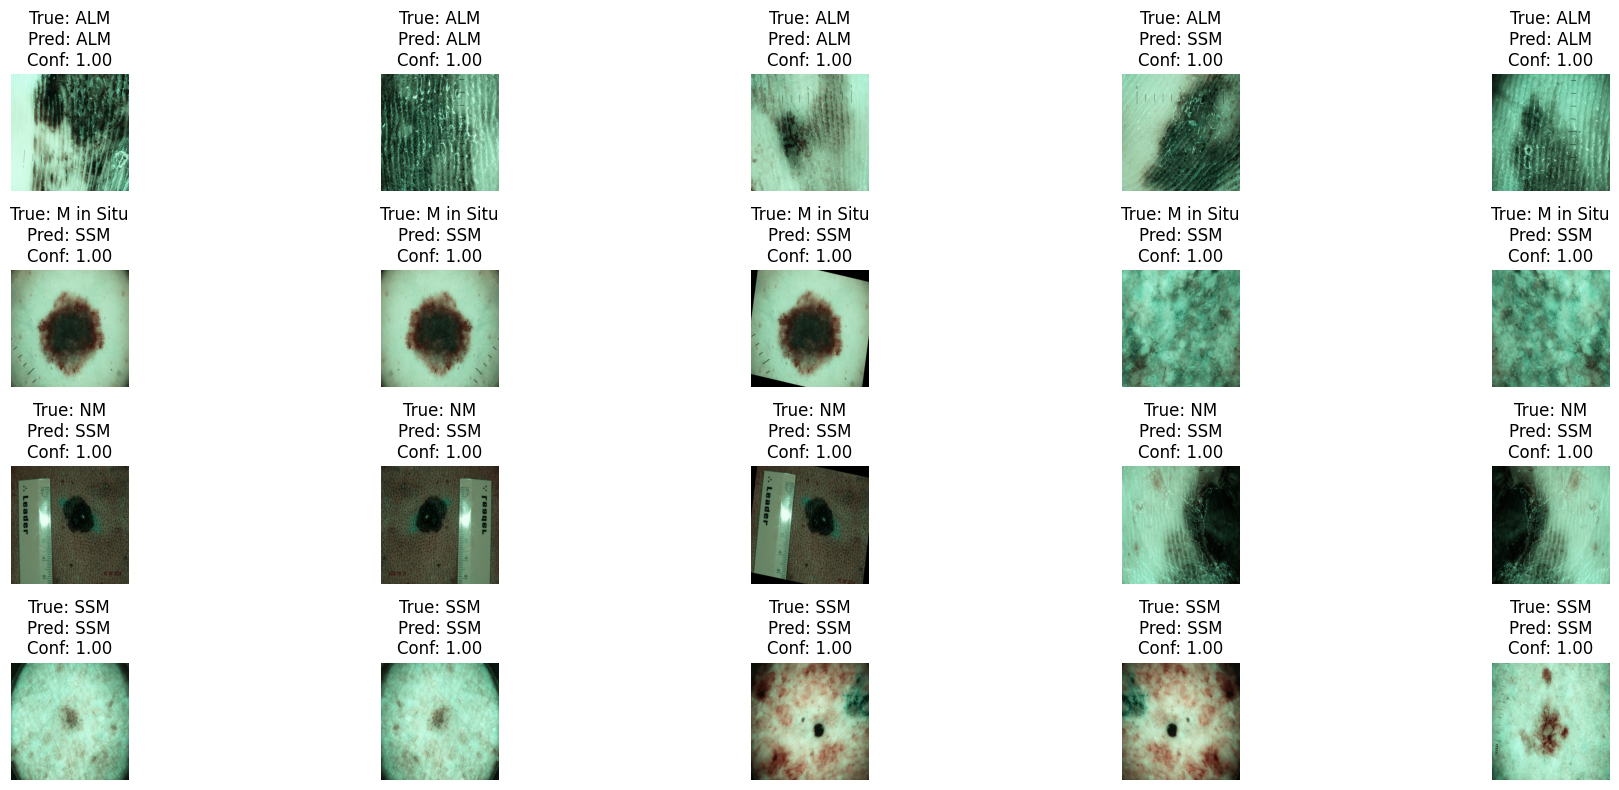

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix
import joblib

# Load the saved SGD classifier model
model_load_path = '/kaggle/working/sgd_classifier_save_model.pkl'
sgd_classifier = joblib.load(model_load_path)
print(f"Model loaded from {model_load_path}")

# Function to get 5 images per class with true and predicted labels
def get_images_by_class(data_loader, num_images=5):
    images, true_labels, predicted_labels, confidences = [], [], [], []

    with torch.no_grad():
        class_count = {class_name: 0 for class_name in range(len(data_loader.dataset.classes))}
        
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1).cpu().numpy()
            preds = sgd_classifier.predict(output)
            probs = sgd_classifier.predict_proba(output)
            
            for i in range(len(lbls)):
                if class_count[lbls[i].item()] < num_images:
                    images.append(inputs[i].cpu().numpy())
                    true_labels.append(lbls[i].item())
                    predicted_labels.append(preds[i])
                    confidences.append(probs[i][preds[i]])
                    class_count[lbls[i].item()] += 1

                # Break once we have enough images for each class
                if all(count >= num_images for count in class_count.values()):
                    break

            if all(count >= num_images for count in class_count.values()):
                break

    return images, true_labels, predicted_labels, confidences

# Get 5 images per class
images, true_labels, predicted_labels, confidences = get_images_by_class(test_loader, num_images=5)

# Define a function to denormalize the images for visualization
def denormalize(img):
    img = img * np.array([0.229, 0.224, 0.225]).reshape((3, 1, 1))
    img = img + np.array([0.485, 0.456, 0.406]).reshape((3, 1, 1))
    return np.clip(img, 0, 1)

# Display images in a grid with predictions
num_classes = len(test_dataset.classes)
fig, axes = plt.subplots(num_classes, 5, figsize=(20, num_classes * 2))  # Set 5 columns for 5 images per class

for i in range(num_classes):
    class_images = [(img, true, pred, conf) for img, true, pred, conf in zip(images, true_labels, predicted_labels, confidences) if true == i]
    
    for j in range(5):
        img, true, pred, conf = class_images[j]
        img = denormalize(img)  # Denormalize for visualization
        img = np.transpose(img, (1, 2, 0))  # Change from CHW to HWC format for plotting

        ax = axes[i, j]
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"True: {test_dataset.classes[true]}\nPred: {test_dataset.classes[pred]}\nConf: {conf:.2f}")

plt.tight_layout()
plt.show()
